### Import Library

In [1]:
import pandas as pd
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from tqdm import tqdm

### Load Data Hasil Preprocessing

In [2]:
df = pd.read_csv("../../data/preprocessing/hasil_preprocessing.csv")

# pastikan kolom tersedia
texts = df['original_text'].astype(str).tolist()

df.head(5)

,text,original_text,clean_text
0,@jokowi @prabowo Adili Jokowi,adili jokowi,adil jokowi
1,@jokowi @prabowo Semoga pak prabowo ngga kayak...,semoga pak prabowo ngga kayak gini ya pak,moga pak prabowo tidak kayak begini pak
2,@jokowi @prabowo Siap siap ya MULYONO semua me...,siap siap ya mulyono semua memanggilmu,siap siap mulyono semua panggil
3,@jokowi @prabowo Kenapa pilih Poto yg ini? Bia...,kenapa pilih poto yg ini biar masih berkesan s...,pilih foto biar kesan siapa tuan
4,@jokowi @prabowo Loe bayar nih utang https://t...,loe bayar nih utang,lo bayar nih utang


### Load Model RoBERTa

In [3]:
MODEL_NAME = "w11wo/indonesian-roberta-base-sentiment-classifier"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

### Pakai Device

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

print(f"Device menggunakan: {device}")

Device menggunakan: cpu


### Label Mapping

In [5]:
# cek mapping model
print(model.config.id2label)

label_mapping = {
    0: "positive",
    1: "neutral",
    2: "negative"
}

{0: 'positive', 1: 'neutral', 2: 'negative'}


### Prediction Function

In [6]:
def predict_sentiment(text):

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)

    logits = outputs.logits
    predicted_class = torch.argmax(logits, dim=1).item()

    label = model.config.id2label[predicted_class]

    return label

### Inference

In [7]:
predictions = []

for text in tqdm(texts):
    pred = predict_sentiment(text)
    predictions.append(pred)


# Save Hasil
df['label_roberta'] = predictions

# simpan hasil
df.to_csv(
    "../../data/labeled/roberta_labeled.csv",
    index=False
)

print("Pseudo-labeling RoBERTa selesai")

100%|██████████| 48546/48546 [47:18<00:00, 17.10it/s]  


Pseudo-labeling RoBERTa selesai


### Distribusi Label

In [8]:
label_counts = df['label_roberta'].value_counts()

label_percent = (
    df['label_roberta']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

distribution = pd.DataFrame({
    'Jumlah': label_counts,
    'Persentase (%)': label_percent
})

print(distribution)

               Jumlah  Persentase (%)
label_roberta                        
negative        28209           58.11
neutral         11228           23.13
positive         9109           18.76


### Visualisasi Label

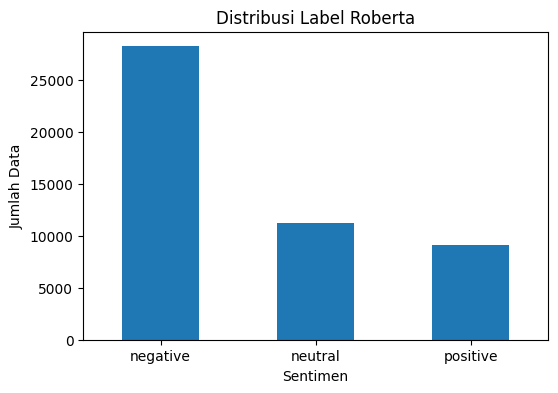

In [9]:
label_counts = df['label_roberta'].value_counts()

plt.figure(figsize=(6,4))
label_counts.plot(kind='bar')
plt.title('Distribusi Label Roberta')
plt.xlabel('Sentimen')
plt.ylabel('Jumlah Data')
plt.xticks(rotation=0)
plt.show()

In [10]:
test_texts = [
    "saya sangat senang",
    "saya sangat marah",
    "kinerja pemerintahnya agak lucu"
]

for text in test_texts:
    print(text)
    print(predict_sentiment(text))
    print()

saya sangat senang
positive

saya sangat marah
negative

kinerja pemerintahnya agak lucu
negative

